# Hyperparameter sweep analysis

Compares PPO, SAC and TD3 sweep results to identify the best configuration per algorithm and across algorithms.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", palette="tab10")
RESULTS = Path("results")

## 1. Load data

In [2]:
ppo = pd.read_csv(RESULTS / "sweep_results_ppo.csv", index_col=0)
sac = pd.read_csv(RESULTS / "sweep_results_sac.csv", index_col=0)
td3 = pd.read_csv(RESULTS / "sweep_results_td3.csv", index_col=0)

# Tag each with its algorithm
ppo["algo"] = "PPO"
sac["algo"] = "SAC"
td3["algo"] = "TD3"

print(f"PPO runs: {len(ppo)}  |  SAC runs: {len(sac)}  |  TD3 runs: {len(td3)}")

PPO runs: 144  |  SAC runs: 48  |  TD3 runs: 95


## 2. Best run per algorithm

In [3]:
def best_run(df, n=5):
    cols = [c for c in df.columns if c not in {"run_name", "algo", "n_evals", "timesteps_reached"}]
    return df.nlargest(n, "best_mean_reward")[cols].reset_index(drop=True)

print("=== PPO top 5 ===")
display(best_run(ppo))

print("\n=== SAC top 5 ===")
display(best_run(sac))

print("\n=== TD3 top 5 ===")
display(best_run(td3))

=== PPO top 5 ===


,lr,ent,steps,gamma,epochs,best_mean_reward,final_mean_reward
0,0.0003,0.02,512,0.95,5,3.595085,2.593747
1,0.0003,0.01,512,0.99,10,3.551099,0.981067
2,0.0002,0.02,512,0.99,5,3.550579,1.992540
3,0.0003,0.00,512,0.95,10,3.507843,1.327197
4,0.0003,0.00,512,0.95,5,3.332194,1.180875



=== SAC top 5 ===


,lr,bs,warmup,gamma,best_mean_reward,final_mean_reward
0,0.00005,512,500,0.95,2.784406,2.635019
1,0.00030,256,1500,0.95,2.644423,0.691009
2,0.00010,256,500,0.95,2.530871,1.084909
3,0.00100,512,500,0.95,2.518117,0.863982
4,0.00005,512,1500,0.95,2.460290,0.396337



=== TD3 top 5 ===


,lr,bs,noise,warmup,gamma,best_mean_reward,final_mean_reward
0,0.00010,512,0.1,500,0.99,3.655188,1.242399
1,0.00005,512,0.2,1000,0.99,3.577749,1.671252
2,0.00005,256,0.1,1500,0.95,3.572969,1.716157
3,0.00005,256,0.2,1000,0.95,3.572826,2.024105
4,0.00010,256,0.1,1500,0.99,3.566994,0.932518


## 3. Cross-algorithm comparison

In [4]:
summary = pd.DataFrame([
    {"algo": "PPO", "n_runs": len(ppo),
     "best":  ppo["best_mean_reward"].max(),
     "median_best": ppo["best_mean_reward"].median(),
     "best_final": ppo.loc[ppo["best_mean_reward"].idxmax(), "final_mean_reward"],
     "best_run": ppo.loc[ppo["best_mean_reward"].idxmax(), "run_name"]},
    {"algo": "SAC", "n_runs": len(sac),
     "best":  sac["best_mean_reward"].max(),
     "median_best": sac["best_mean_reward"].median(),
     "best_final": sac.loc[sac["best_mean_reward"].idxmax(), "final_mean_reward"],
     "best_run": sac.loc[sac["best_mean_reward"].idxmax(), "run_name"]},
    {"algo": "TD3", "n_runs": len(td3),
     "best":  td3["best_mean_reward"].max(),
     "median_best": td3["best_mean_reward"].median(),
     "best_final": td3.loc[td3["best_mean_reward"].idxmax(), "final_mean_reward"],
     "best_run": td3.loc[td3["best_mean_reward"].idxmax(), "run_name"]},
])
display(summary)

,algo,n_runs,best,median_best,best_final,best_run
0,PPO,144,3.595085,2.182635,2.593747,lr=0.0003_ent=0.02_steps=512_gamma=0.95_epochs=5
1,SAC,48,2.784406,2.129311,2.635019,lr=5e-05_bs=512_warmup=500_gamma=0.95
2,TD3,95,3.655188,0.000000,1.242399,lr=0.0001_bs=512_noise=0.1_warmup=500_gamma=0.99


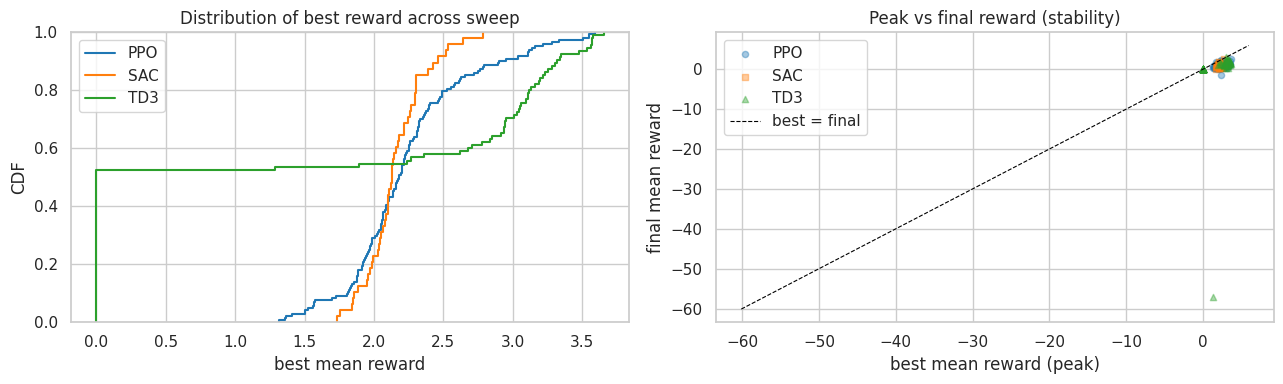

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Distribution of best_mean_reward per algo
for algo, df in [("PPO", ppo), ("SAC", sac), ("TD3", td3)]:
    axes[0].ecdf(df["best_mean_reward"], label=algo)
axes[0].set_xlabel("best mean reward")
axes[0].set_ylabel("CDF")
axes[0].set_title("Distribution of best reward across sweep")
axes[0].legend()

# best vs final reward (stability)
for algo, df, marker in [("PPO", ppo, "o"), ("SAC", sac, "s"), ("TD3", td3, "^")]:
    axes[1].scatter(df["best_mean_reward"], df["final_mean_reward"],
                    alpha=0.4, marker=marker, label=algo, s=20)
lims = [min(axes[1].get_xlim()[0], axes[1].get_ylim()[0]),
        max(axes[1].get_xlim()[1], axes[1].get_ylim()[1])]
axes[1].plot(lims, lims, "k--", lw=0.8, label="best = final")
axes[1].set_xlabel("best mean reward (peak)")
axes[1].set_ylabel("final mean reward")
axes[1].set_title("Peak vs final reward (stability)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. PPO — parameter sensitivity

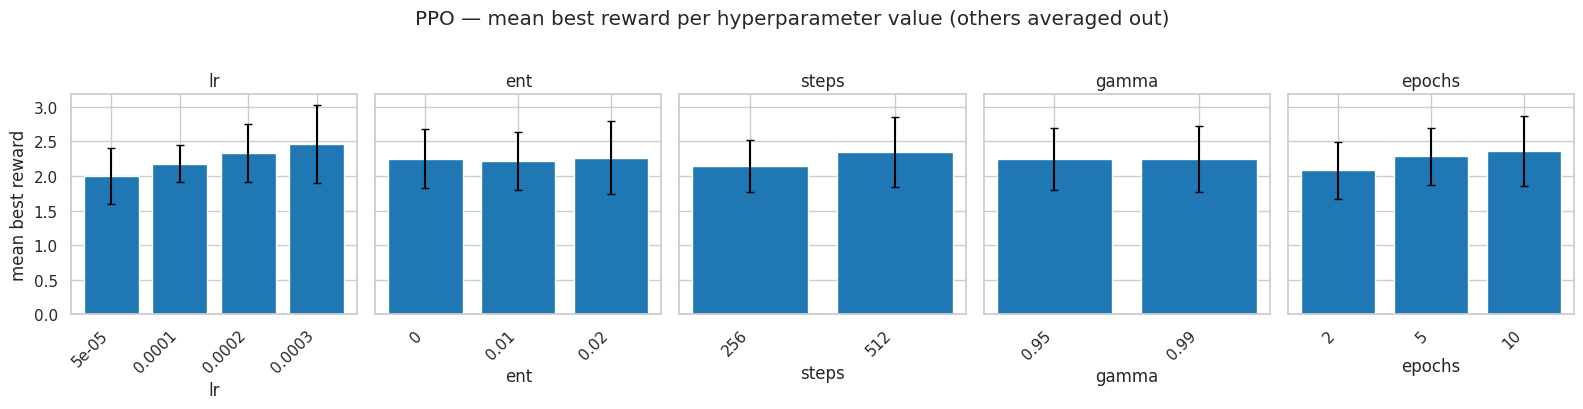

In [6]:
ppo_params = ["lr", "ent", "steps", "gamma", "epochs"]

fig, axes = plt.subplots(1, len(ppo_params), figsize=(16, 4), sharey=True)
for ax, param in zip(axes, ppo_params):
    grouped = ppo.groupby(param)["best_mean_reward"]
    means = grouped.mean().sort_index()
    errs  = grouped.std().sort_index()
    ax.bar(range(len(means)), means.values, yerr=errs.values, capsize=3)
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels([f"{v:.4g}" for v in means.index], rotation=45, ha="right")
    ax.set_title(param)
    ax.set_xlabel(param)
axes[0].set_ylabel("mean best reward")
fig.suptitle("PPO — mean best reward per hyperparameter value (others averaged out)", y=1.02)
plt.tight_layout()
plt.show()

## 5. SAC — parameter sensitivity

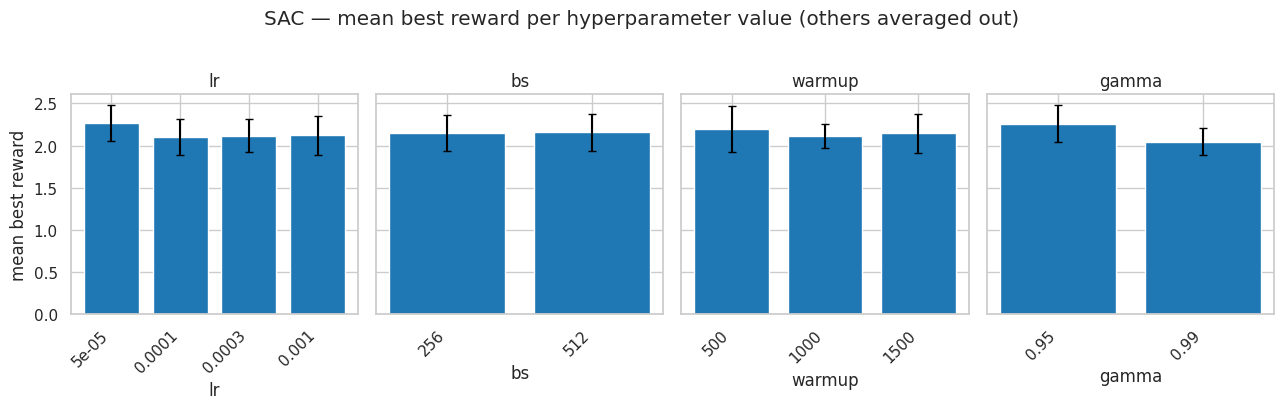

In [7]:
sac_params = ["lr", "bs", "warmup", "gamma"]

fig, axes = plt.subplots(1, len(sac_params), figsize=(13, 4), sharey=True)
for ax, param in zip(axes, sac_params):
    grouped = sac.groupby(param)["best_mean_reward"]
    means = grouped.mean().sort_index()
    errs  = grouped.std().sort_index()
    ax.bar(range(len(means)), means.values, yerr=errs.values, capsize=3)
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels([f"{v:.4g}" for v in means.index], rotation=45, ha="right")
    ax.set_title(param)
    ax.set_xlabel(param)
axes[0].set_ylabel("mean best reward")
fig.suptitle("SAC — mean best reward per hyperparameter value (others averaged out)", y=1.02)
plt.tight_layout()
plt.show()

## 6. TD3 — parameter sensitivity

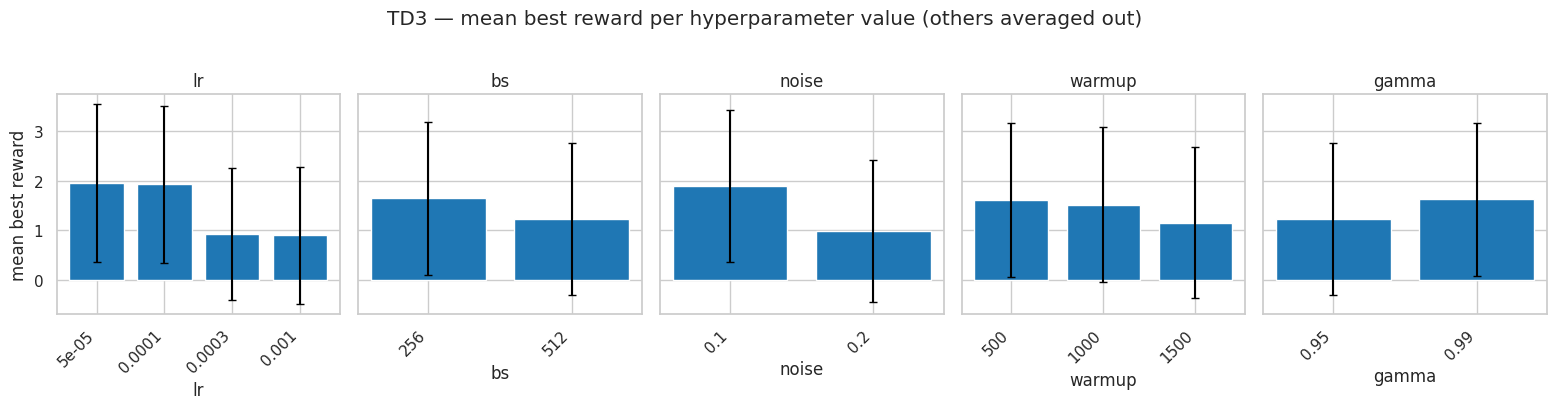

In [8]:
td3_params = ["lr", "bs", "noise", "warmup", "gamma"]

fig, axes = plt.subplots(1, len(td3_params), figsize=(16, 4), sharey=True)
for ax, param in zip(axes, td3_params):
    grouped = td3.groupby(param)["best_mean_reward"]
    means = grouped.mean().sort_index()
    errs  = grouped.std().sort_index()
    ax.bar(range(len(means)), means.values, yerr=errs.values, capsize=3)
    ax.set_xticks(range(len(means)))
    ax.set_xticklabels([f"{v:.4g}" for v in means.index], rotation=45, ha="right")
    ax.set_title(param)
    ax.set_xlabel(param)
axes[0].set_ylabel("mean best reward")
fig.suptitle("TD3 — mean best reward per hyperparameter value (others averaged out)", y=1.02)
plt.tight_layout()
plt.show()

## 7. Correlation heatmaps (parameter vs reward)

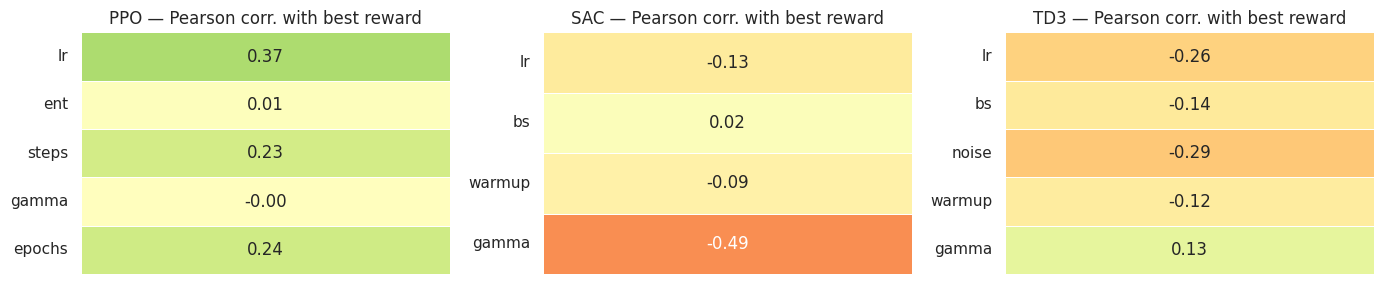

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))

for ax, (algo, df, params) in zip(axes, [
    ("PPO", ppo, ppo_params),
    ("SAC", sac, sac_params),
    ("TD3", td3, td3_params),
]):
    corr = df[params + ["best_mean_reward"]].corr()[["best_mean_reward"]].drop("best_mean_reward")
    sns.heatmap(corr, ax=ax, annot=True, fmt=".2f", cmap="RdYlGn",
                vmin=-1, vmax=1, cbar=False, linewidths=0.5)
    ax.set_title(f"{algo} — Pearson corr. with best reward")
    ax.set_ylabel("")
    ax.set_xticklabels([])

plt.tight_layout()
plt.show()

## 8. Final recommendation

In [10]:
def describe_best(algo, df):
    row = df.loc[df["best_mean_reward"].idxmax()]
    meta = {"best_mean_reward", "final_mean_reward", "n_evals", "timesteps_reached", "algo", "run_name"}
    params = {k: v for k, v in row.items() if k not in meta}
    stability = row["final_mean_reward"] / row["best_mean_reward"]
    print(f"{'─'*60}")
    print(f"  {algo}  best run: {row['run_name']}")
    print(f"  best reward : {row['best_mean_reward']:.4f}")
    print(f"  final reward: {row['final_mean_reward']:.4f}  (stability {stability:.0%})")
    print(f"  params      : {params}")

for algo, df in [("PPO", ppo), ("SAC", sac), ("TD3", td3)]:
    describe_best(algo, df)

# Overall winner
all_bests = {
    "PPO": ppo["best_mean_reward"].max(),
    "SAC": sac["best_mean_reward"].max(),
    "TD3": td3["best_mean_reward"].max(),
}
winner = max(all_bests, key=all_bests.get)
print(f"\n{'═'*60}")
print(f"  Overall best algorithm: {winner}  ({all_bests[winner]:.4f})")
print(f"{'═'*60}")

────────────────────────────────────────────────────────────
  PPO  best run: lr=0.0003_ent=0.02_steps=512_gamma=0.95_epochs=5
  best reward : 3.5951
  final reward: 2.5937  (stability 72%)
  params      : {'lr': np.float64(0.0003), 'ent': np.float64(0.02), 'steps': np.int64(512), 'gamma': np.float64(0.95), 'epochs': np.int64(5)}
────────────────────────────────────────────────────────────
  SAC  best run: lr=5e-05_bs=512_warmup=500_gamma=0.95
  best reward : 2.7844
  final reward: 2.6350  (stability 95%)
  params      : {'lr': np.float64(5e-05), 'bs': np.int64(512), 'warmup': np.int64(500), 'gamma': np.float64(0.95)}
────────────────────────────────────────────────────────────
  TD3  best run: lr=0.0001_bs=512_noise=0.1_warmup=500_gamma=0.99
  best reward : 3.6552
  final reward: 1.2424  (stability 34%)
  params      : {'lr': np.float64(0.0001), 'bs': np.int64(512), 'noise': np.float64(0.1), 'warmup': np.int64(500), 'gamma': np.float64(0.99)}

═════════════════════════════════════════